In [32]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import nlopt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

from scipy.optimize import minimize_scalar
from sklearn.model_selection import KFold
from scipy.optimize import brentq

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

%load_ext autoreload
%autoreload 2

# 現在のフォルダの「1つ上の階層（../）」をシステムのパスに追加する
sys.path.append(os.path.abspath(".."))

#作成したモジュールをインポート
# from src.data_prep import *
# from src.nominal_speed_func import *
# from src.cooperation_surplus import *
# from src.macroscopic_data import *
# from src.traffic_regime import *
from src.whole_pipeline import *


#feet を　メートルに変換する係数 1feet=0.3048m
FT_TO_M = 0.3048

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### パラメータキャッシュ

In [26]:
# ============================================================
# キャッシュ済みテストパラメータ
# (2026-09-02の実行結果。カーネル再起動のたびにISRESを再実行しなくて済むように、
#  実際の関数の戻り値と同じ形式でハードコードしたもの)
# ============================================================
#名目速度関数の推定
results_cc_strong_constraint = {
    'mode_id': 1, 'ub': 12.760, 'uf': 118.369, 'rhoc': 12.676,
    'theta1': 4.999, 'theta2': 0.343, 'test_mae': 7.055
}

results_ct_strong_constraint = {
    'mode_id': 2, 'ub': 10.674, 'uf': 109.230, 'rhoc': 14.120,
    'theta1': 2.167, 'theta2': 0.425, 'test_mae': 6.564
}

results_tt_strong_constraint = {
    'mode_id': 4, 'uf': 68.473, 'rhoc': 18.542, 'test_mae': 5.862
}

results_tc_strong_constraint = {
    'mode_id': 3, 'uf': 96.717, 'rhoc': 26.806, 'test_mae': 6.717
}

results_a2 = {
    'mode_id': 2, 'scaling_param': 0.4687, 'test_mae': 6.789
}

results_b1 = {
    'mode_id': 3, 'scaling_param': 1.8331, 'test_mae': 6.106
}

#論文値　これで推測すれば、論文の結果が再現できるはず
results_cc_paper_km =  {'mode_id': 1, 'ub': 12.762, 'uf': 118.367, 'rhoc': 12.676,
            'theta1': 4.995, 'theta2': 0.2309, 'test_mae': 6.73}
results_ct_paper_km =  {'mode_id': 2, 'ub': 10.670, 'uf': 109.227, 'rhoc': 14.124,
            'theta1': 2.165, 'theta2': 0.2673, 'test_mae': 7.55}

results_tt_paper_km =  {'mode_id': 4, 'uf': 68.478,'rhoc': 25.936, 'test_mae': 3.94}
results_tc_paper_km =  {'mode_id': 3, 'uf': 96.722,'rhoc': 49.393, 'test_mae': 12.57}

results_a2_paper_km = {
    'mode_id': 2, 'scaling_param': 0.4528, 'test_mae': 7.37
}

results_b1_paper_km = {
    'mode_id': 3, 'scaling_param': 2.5996, 'test_mae': 10.40
}

### パイプライン一括実行

In [ ]:
data = prepare_data()   # 数分かかる。1回だけ実行する

In [34]:
car_pp = {'ub': 12.762, 'uf': 118.367, 'rhoc': 12.676, 'theta1': 4.995, 'theta2': 0.2309}
trk_pp = {'uf': 68.478, 'rhoc': 25.936}

#out = run_pipeline(data, car_pp, trk_pp, a2=0.4528, b1=2.5996, scaling='inverted', eps_kmh=2.0)

#out = run_pipeline(data, results_cc_strong_constraint, results_tt_strong_constraint, a2=results_a2["scaling_param"], b1=results_b1["scaling_param"], scaling='inverted', eps_kmh=6.0)
# ===== Step 3〜6 =====
out = run_pipeline(
    data,
    car_params=results_cc_strong_constraint,             # 車(C-C)の名目速度関数
    truck_params=results_tt_strong_constraint,           # トラック(T-T)の名目速度関数
    a2=results_a2["scaling_param"],                     # 数値でも fit_scaling_parameter_* の戻り値(dict)でもよい
    b1=results_b1["scaling_param"],
    scaling='printed',            # 'printed'（論文の記載どおり） / 'inverted'
    eps_kmh=6.0,                   # 数値（共通） / (車のε, トラックのε)
    skip_sec_warmup=100,           # 各time_periodの最初に除外する秒数
    skip_sec_cooldown=100,         # 各time_periodの最後に除外する秒数
    n_car=None,                    # Eq.15の台数。Noneならdf_finalから数える
    n_truck=None,
    pce_truck=1.5,                 # トラックの乗用車換算係数（論文の値）
    w1=0.5,                        # 損失関数のクラスの重み（論文の値）
    w2=0.5,
    test_size=0.3,                 # テストデータの割合（論文の値）
    k=10,                          # 交差検証の分割数（論文の値）
    random_state=42,               # データの分け方を固定する乱数の種
    bounds=(0.0, 1.0),             # λの探索範囲（論文の定義どおり）
)

out['summary']

# 設定を変えて比べる例
rows = []
for scaling in ['printed', 'inverted']:
    for eps in [1, 2, 3, 5]:
        rows.append(run_pipeline(data, results_cc_strong_constraint, results_tt_strong_constraint, results_a2["scaling_param"], results_b1["scaling_param"], scaling, eps)['summary'])
pd.DataFrame(rows)

===== scaling=printed, a2=0.4687, b1=1.8331, eps=6.0, 除外: 最初100秒・最後100秒 =====
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件
1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 4,079件）
交通状態を判定(eps: 車 6.00, トラック 6.00 km/h): 判定対象 4,959件 (対象外 undefined: 87件)
      2-pipe: 829件 (16.72%)
      1-pipe: 3,199件 (64.51%)
      non-NE: 931件 (18.77%)
  Pcoop = 16.72% (論文: 13.83%)
  平均s: 2-pipe = 0.0046, 1-pipe = 0.0028 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 4,959件
  s>0             : 4,054件 (81.75%)
  2-pipe          : 829件 (16.72%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 829件 (16.72%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 0件 (0.00% of 2-pipe)  ← 命題1と不整合
λの推定に使うスナップショット(2-pipe かつ s>0): 829件  (探索範囲: (0.0, 1.0))
  ※警告: λ_hat=0.0000 が探索範囲(0.0, 1.0)の端にあります（境界解）。plot_surplus_split_loss で範囲外の損失の形を確認してください
  学習 580件 / テスト 249件
  10-fold CV: λ = 0.0000 ± 0.0000, 重み付きMAE = 6.147 ± 0.189 km/h
 

,scaling,a2,b1,eps_kmh,n_judged,Pcoop_%,share_1pipe_%,mean_s_2pipe,mean_s_1pipe,n_coop,lambda_hat,mae_weighted_kmh,zeta
0,printed,0.4687,1.8331,1,4374,51.783265,4.458162,0.004177,0.003486,2264,0.000006,3.925780,19.553336
1,printed,0.4687,1.8331,2,4374,48.696845,13.443073,0.004169,0.003537,2130,0.000006,4.094414,19.553336
2,printed,0.4687,1.8331,3,4374,41.312300,27.503429,0.004265,0.003270,1806,0.000006,4.299112,19.553336
3,printed,0.4687,1.8331,5,4374,24.759945,52.629172,0.004493,0.003225,1083,0.000006,5.644656,19.553336
4,inverted,0.4687,1.8331,1,4374,58.687700,3.155007,0.060023,0.061277,2567,0.606227,3.443178,7.060730
5,inverted,0.4687,1.8331,2,4374,57.590306,9.899406,0.059391,0.061897,2519,0.607428,3.526066,7.035975
6,inverted,0.4687,1.8331,3,4374,51.531779,21.216278,0.059752,0.058123,2254,0.583711,3.808690,7.524715
7,inverted,0.4687,1.8331,5,4374,35.619570,46.159122,0.063762,0.055177,1558,0.463255,4.111848,10.007005


===== scaling=inverted, a2=0.4528, b1=2.5996, eps=2.0, 除外: 最初100秒・最後200秒 =====
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の200秒を除外: 10,846件 → 8,820件
1-pipe速度を計算(scaling=inverted): 4,446スナップショット中、4,446件で解を取得
最小道路占有を計算: 4,446スナップショット中、4,446件で計算完了
協力余剰sを計算: 4,446スナップショット中、4,446件で計算完了（うちs>0: 4,394件）
交通状態を判定(eps: 車 2.00, トラック 2.00 km/h): 判定対象 4,374件 (対象外 undefined: 72件)
      2-pipe: 559件 (12.78%)
      1-pipe: 318件 (7.27%)
      non-NE: 3,497件 (79.95%)
  Pcoop = 12.78% (論文: 13.83%)
  平均s: 2-pipe = 0.1666, 1-pipe = 0.1554 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 4,374件
  s>0             : 4,374件 (100.00%)
  2-pipe          : 559件 (12.78%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 559件 (12.78%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 0件 (0.00% of 2-pipe)  ← 命題1と不整合
λの推定に使うスナップショット(2-pipe かつ s>0): 559件  (探索範囲: (0.0, 1.0))
  学習 391件 / テスト 168件
  10-fold CV: λ = 0.8048 ± 0.0018, 重み付きMAE = 3.683 ± 0.209 km/h
  λ_hat = 0.8049  (論文: 0.8067)
  テストMAE: 車 5.158, トラック 2.408, 重み付き 3.783 km/h
           = 

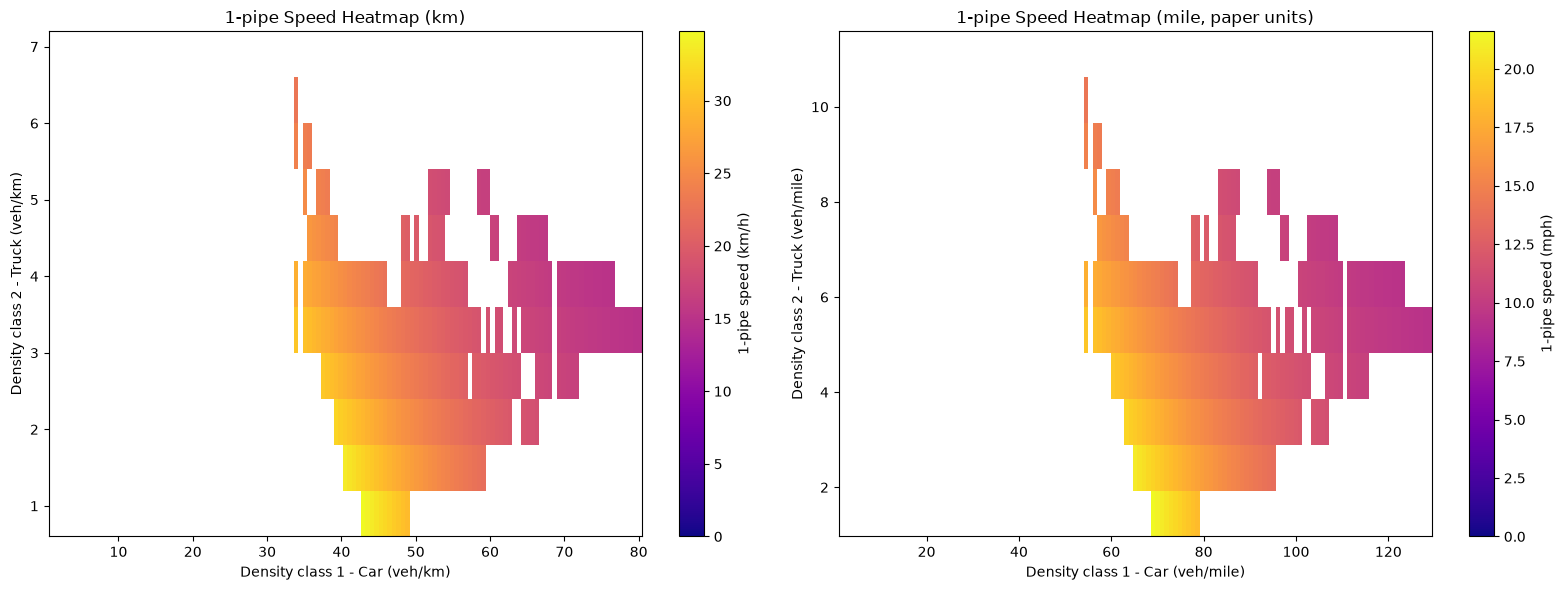

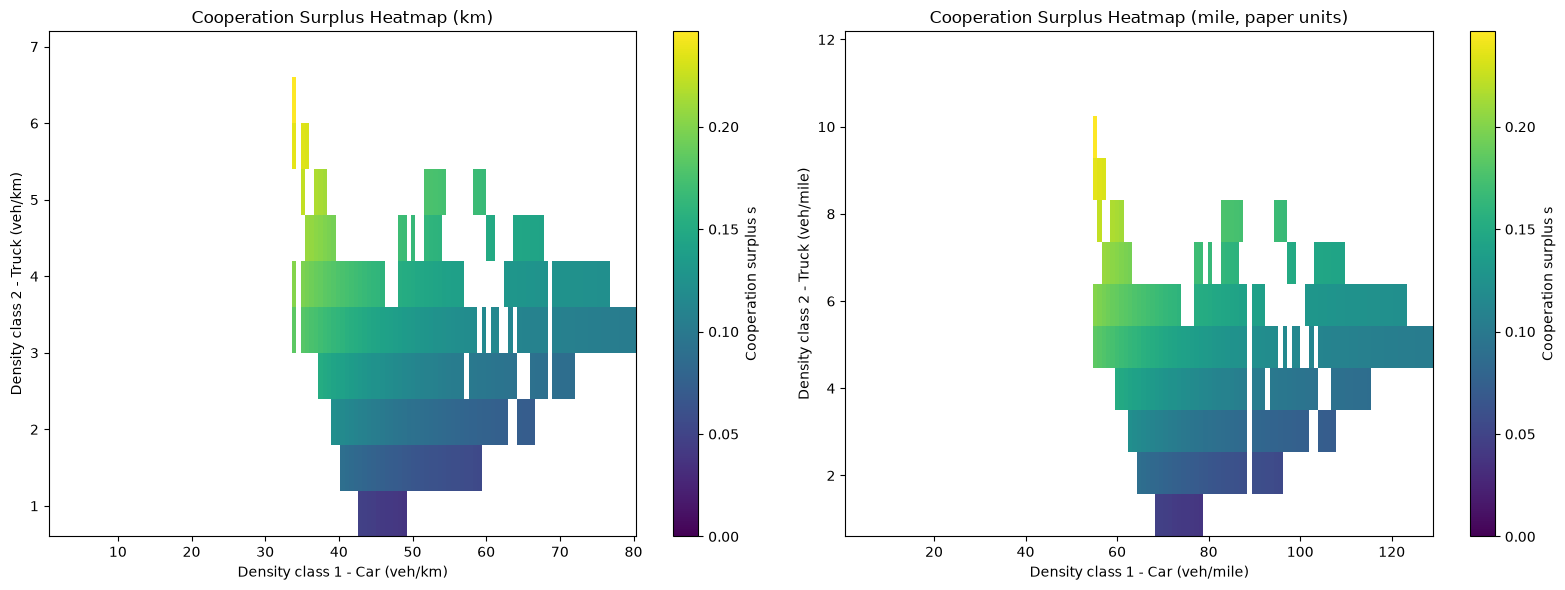

各time_periodの最初の0秒を除外: 4,446件 → 4,446件


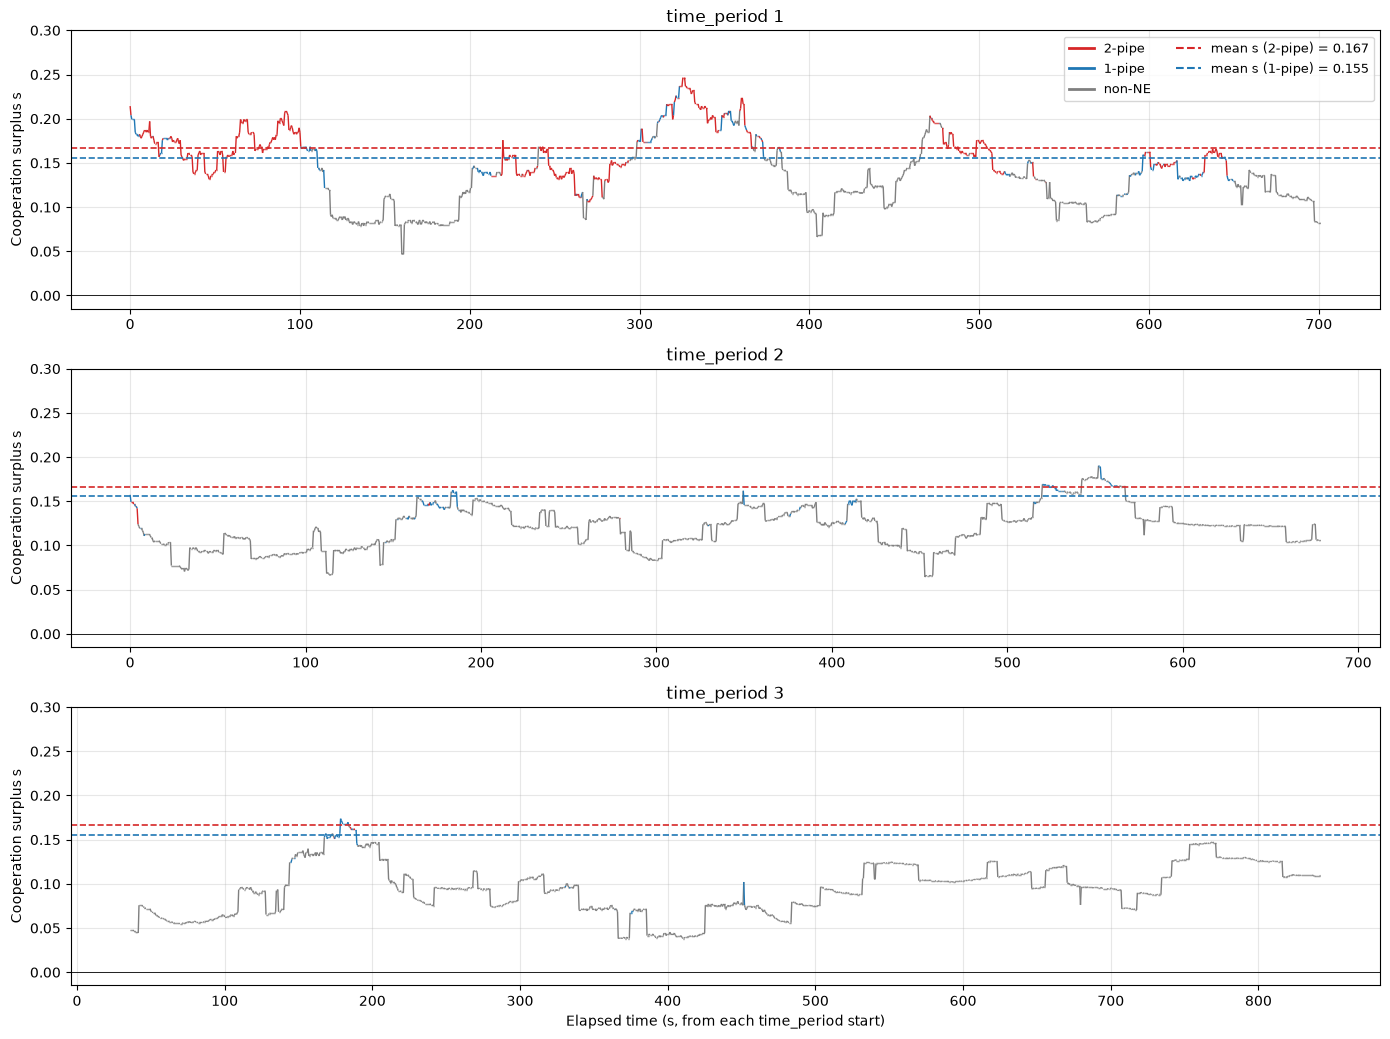

regime別の平均s: 2-pipe=0.167, 1-pipe=0.155  (論文: 2-pipe=0.15, 1-pipe=0.11)


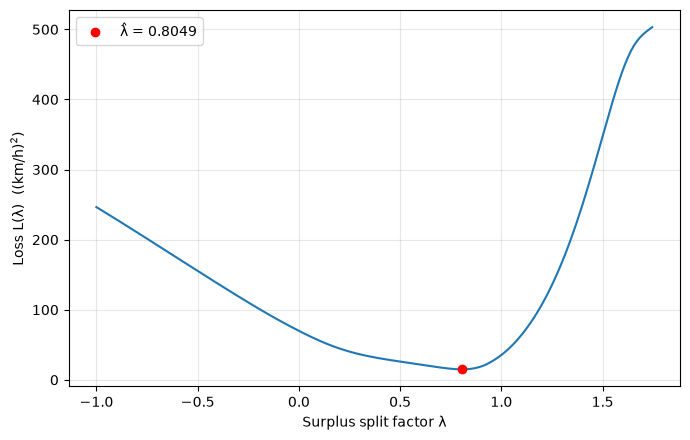

In [35]:
out = run_pipeline(data, car_pp, trk_pp, a2=0.4528, b1=2.5996, scaling='inverted', eps_kmh=2.0)

#fig11（df_s には u_1pipe の列も入っているので、df_1pipe の代わりに使える）
plot_1pipe_speed_heatmap(out['df_s'], bin_width1=0.6, bin_width2=0.6, max_rho1=80, max_rho2=7, min_count=3)
#fig12
plot_cooperation_surplus_heatmap(out['df_s'], bin_width1=0.6, bin_width2=0.6, max_rho1=80, max_rho2=7, min_count=3)
#fig13（run_pipeline の中で最初と最後をもう除外しているので skip_sec=0）
plot_surplus_by_regime(out['df_regime'], skip_sec=0, ylim=(-0.015, 0.30))
#fig17（λを推定できたときだけ描ける）
if out['lambda'] is not None:
    plot_surplus_split_loss(out['lambda']['train'], car_pp, trk_pp, out['lambda']['lambda_hat'])

### 一連のパイプライン


In [3]:
#step 0
df = load_trajectory_data() # データの読み込みと前処理
df_rem_noise = remove_flicker_noise(df, col='Preceding', threshold=10) #　フリッカリングノイズを除去
df_clean = remove_flicker_noise(df_rem_noise, col='Lane_ID', threshold=10) 
df_clean = recompute_headway_after_flicker(df_clean) #車頭距離を再計算
df_with_pairs = give_pair_id(df_clean) #ペアID付与
df_with_mode = give_mode_id(df_with_pairs, df) #モードID付与
df_valid = filter_valid_pairs(df_with_mode) #追従していない行を除外 追従している車両のみのデータが完成
df_lane = filter_lane(df_valid) #車線フィルタ（Lanes 2, 3, 4のみ）
df_mode = filter_mode(df_lane) #モードフィルタ(車種を限定)
df_duration = filter_duration(df_mode) #追従時間フィルタ
df_cutoff = apply_cutoff(df_duration) #カットオフウィンドウ
df_final = filter_acceleration(df_cutoff).copy() #加速度フィルタ

# # 最終結果の確認
# print(f"\n===最終結果===")
# print(f"行数: {len(df_final):,}")
# print(f"ペア数: {df_final['pair_id'].nunique():,}")
# assign_and_count_pair_type_with_pair_id(df_final)

(4566387, 19)

--フリッカリング除去--
補正されたブロック数: 671
行数: 4,566,387

--フリッカリング除去--
補正されたブロック数: 142
行数: 4,566,387

--フリッカリング補正行の車間距離を座標から再計算--
対象行: 3,225  再計算できた行: 2,472  NaNにした行: 753
  NaNの内訳: 先行車が別車線 345行 / 先行車なし・位置不明・距離0以下 408行
  元の値から1ft超変わった行: 2,284  (元の値が0だった行: 208)

--ペアIDを付与--
総行数: 4,566,387
追従ペア数: 13,827

--モードID別を付与--
総行数: 4,566,387
追従ペア数: 13,827
mode_id
1.0    12337
2.0      438
3.0      549
4.0       42
5.0      461
dtype: int64

--追従していない軌跡データを削除--
フィルタ前の行数: 4,566,387
フィルタ後の行数: 4,359,245
除外された行数: 207,142
ペア数: 13,827

--車線フィルタ(2,3,4レーンを残す)--
フィルタ前: 4,359,245行
フィルタ後: 2,338,830行
除外された行数: 2,020,415行
追従ペア数: 5,780

車線の分布:
Lane_ID
2.0    800339
3.0    689350
4.0    849141
Name: count, dtype: int64

--車種フィルタ(1,2,3,4の追従モードを残す)--
フィルタ前のペア数: 5,780
フィルタ後のペア数: 5,666
除外されたペア数: 114
フィルタ後行数: 2,335,438行

モードID別ペア数:
mode_id
1.0    5067
2.0     237
3.0     326
4.0      36
dtype: int64

--追従時間フィルタ--
フィルタ前のペア数: 5,666
フィルタ後のペア数: 1,570
除外されたペア数: 4,096
フィルタ前の行数: 2,335,438
フィルタ後の行数: 1,487,854

--カットオフウィンドウ-

In [22]:
#step 1
# df_filtered = filter_invalid_headway(df_final, min_spacing_m=4.5, ft_to_m=FT_TO_M)
# df_mdensity = compute_micro_density(df_filtered, ft_to_m=FT_TO_M)
# results_cc_strong_constraint = fit_nominal_speed_logistic( #cc
#     df_mdensity, mode_id=1,
#     lower_bounds=[12.76, 118.36, 12.67, 4.99, 0.001],
#     upper_bounds=[12.77, 118.37, 12.68, 5.00, 100.0], 
#     init_params = [12.762, 118.367, 12.676, 4.995, 0.5]
# )
# results_ct_strong_constraint = fit_nominal_speed_logistic( #ct
#     df_mdensity, mode_id=2,
#     lower_bounds=[10.665, 109.222, 14.119, 2.160, 0.001],
#     upper_bounds=[10.675, 109.232, 14.129, 2.170, 100.0], 
#     init_params = [10.670, 109.227, 14.124, 2.165, 0.5]
# )
# results_tt_strong_constraint = fit_nominal_speed_underwood( #tt
#     df_mdensity, mode_id=4,
#     lower_bounds = [68.473, 1.000],
#     upper_bounds = [68.483, 100.000],
#     init_params = [68.478, 50.000]
# )
# results_tc_strong_constraint = fit_nominal_speed_underwood( #tc
#     df_mdensity, mode_id=3,
#     lower_bounds = [96.717, 1.000],
#     upper_bounds = [96.727, 100.000],
#     init_params = [96.722, 50.000]
# )
# results_a2 = fit_scaling_parameter_logistic(df_mdensity, mode_id=2, nominal_params=results_cc_strong_constraint) #スケーリングパラメータの計算
# results_b1 = fit_scaling_parameter_underwood(df_mdensity, mode_id=3, nominal_params=results_tt_strong_constraint) #スケーリングパラメータの計算

#step 2
df_macro_data_full = compute_macroscopic_data(df, lanes=(2, 3, 4), classes=(2, 3), snapshot_step_frames=5)#マクロ密度の計算

#step 3 _VALID_SCALINGS = ('printed', 'inverted')
df_macro_data = drop_warmup(df_macro_data_full, skip_sec=100)
df_macro_data = drop_cooldown(df_macro_data, skip_sec=100)

df_1pipe = compute_1pipe_speed_for_snapshots( #1-pipe速度の計算
    df_macro_data_full,
    car_params=results_cc_strong_constraint,
    truck_params=results_tt_strong_constraint,
    a2=results_a2['scaling_param'],
    b1=results_b1['scaling_param'],
    scaling='inverted'
)
df_pstar = compute_min_road_share(df_1pipe, car_params=results_cc_strong_constraint, truck_params=results_tt_strong_constraint) #最小道路占有の計算
df_s = compute_cooperation_surplus(df_pstar) #協力余剰の計算

#step 4
df_regime = classify_traffic_regime(df_s, eps_kmh=2.0)  #交通状態の分類

#step 5
df_coop = check_cooperation_existence(df_regime) #協力性の存在

#step 6
#手元推定パラメータでの計算結果
res = estimate_surplus_split(df_coop, results_cc_strong_constraint, results_tt_strong_constraint)
veh_final = df_final[['time_period', 'Vehicle_ID', 'v_Class']].drop_duplicates() #df_final（フィルタ後の追従データ）に出てくる車両の台数で正規化
n_car_A   = (veh_final['v_Class'] == 2).sum()
n_truck_A = (veh_final['v_Class'] == 3).sum()
print(f"(A) df_final: 車 {n_car_A}台, トラック {n_truck_A}台  (論文: 1401台, 39台)")
eq_A = compute_equity_metric(res['lambda_hat'], n_car=n_car_A, n_truck=n_truck_A)


区間長: 545.8 m, 車線数: 3

--マクロ密度・平均速度を計算--
各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件
1-pipe速度を計算(scaling=inverted): 6,246スナップショット中、6,246件で解を取得
最小道路占有を計算: 6,246スナップショット中、6,246件で計算完了
協力余剰sを計算: 6,246スナップショット中、6,246件で計算完了（うちs>0: 5,955件）
交通状態を判定(eps: 車 2.00, トラック 2.00 km/h): 判定対象 5,544件 (対象外 undefined: 702件)
      2-pipe: 2,896件 (52.24%)
      1-pipe: 509件 (9.18%)
      non-NE: 2,139件 (38.58%)
  Pcoop = 52.24% (論文: 13.83%)
  平均s: 2-pipe = 0.0593, 1-pipe = 0.0631 (論文: 0.15, 0.11)
協力性の存在判定: 判定対象 5,544件
  s>0             : 5,544件 (100.00%)
  2-pipe          : 2,896件 (52.24%)  ← 論文Pcoop=13.83%
  2-pipe かつ s>0 : 2,896件 (52.24%)  ← 協力性あり(Step6で使う)
  2-pipe かつ s<=0: 0件 (0.00% of 2-pipe)  ← 命題1と不整合
λの推定に使うスナップショット(2-pipe かつ s>0): 2,896件  (探索範囲: (0.0, 1.0))
  学習 2,027件 / テスト 869件
  10-fold CV: λ = 0.6276 ± 0.0022, 重み付きMAE = 3.376 ± 0.122 km/h
  λ_hat = 0.6279  (論文: 0.8067)
  テストMAE: 車 3.870, トラック 3.103, 重み付き 3.486 km/h
           = 車 2.405, トラック 1.928, 重み付き 2

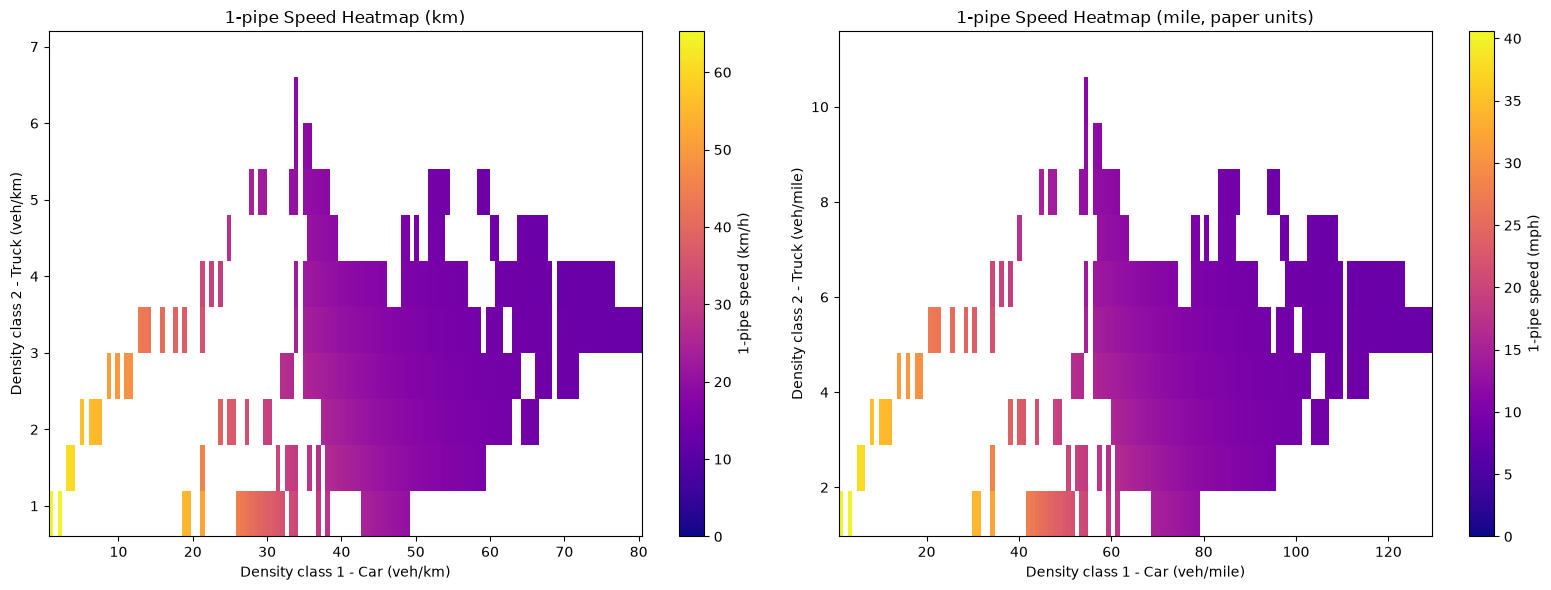

(              (0.599, 1.2]  (1.2, 1.8]  (1.8, 2.4]  (2.4, 3.0]  (3.0, 3.6]  \
 (0.599, 1.2]     65.288801         NaN   64.639916         NaN         NaN   
 (1.2, 1.8]             NaN         NaN         NaN         NaN   60.850702   
 (1.8, 2.4]             NaN         NaN         NaN         NaN         NaN   
 (2.4, 3.0]             NaN         NaN         NaN         NaN         NaN   
 (3.0, 3.6]             NaN         NaN         NaN         NaN         NaN   
 (3.6, 4.2]             NaN         NaN         NaN         NaN         NaN   
 (4.2, 4.8]             NaN         NaN         NaN         NaN         NaN   
 (4.8, 5.4]             NaN         NaN         NaN         NaN         NaN   
 (5.4, 6.0]             NaN         NaN         NaN         NaN         NaN   
 (6.0, 6.6]             NaN         NaN         NaN         NaN         NaN   
 (6.6, 7.2]             NaN         NaN         NaN         NaN         NaN   
 
               (3.6, 4.2]  (4.2, 4.8]  (4.8, 5.4] 

In [17]:
#fig11
plot_1pipe_speed_heatmap(df_1pipe, bin_width1=0.6, bin_width2=0.6,max_rho1=80, max_rho2=7,min_count=3)

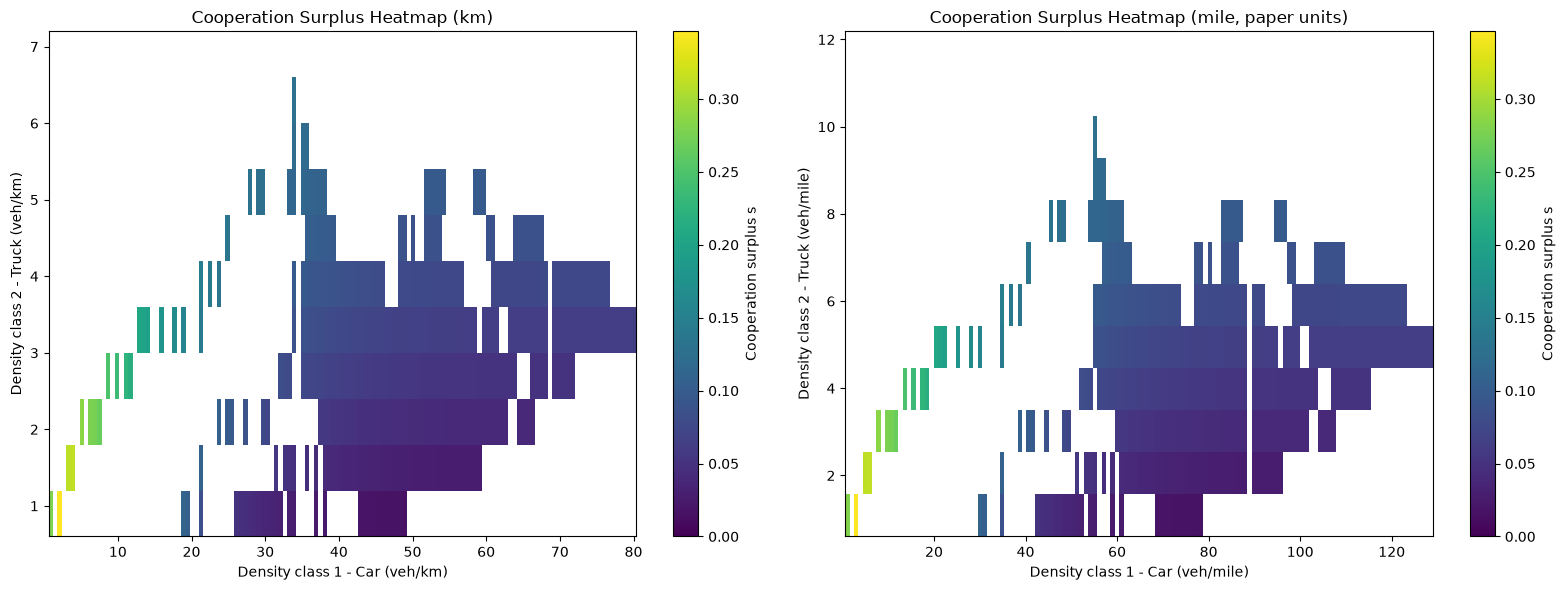

(              (0.599, 1.2]  (1.2, 1.8]  (1.8, 2.4]  (2.4, 3.0]  (3.0, 3.6]  \
 (0.599, 1.2]      0.280785         NaN    0.346348         NaN         NaN   
 (1.2, 1.8]             NaN         NaN         NaN         NaN     0.31251   
 (1.8, 2.4]             NaN         NaN         NaN         NaN         NaN   
 (2.4, 3.0]             NaN         NaN         NaN         NaN         NaN   
 (3.0, 3.6]             NaN         NaN         NaN         NaN         NaN   
 (3.6, 4.2]             NaN         NaN         NaN         NaN         NaN   
 (4.2, 4.8]             NaN         NaN         NaN         NaN         NaN   
 (4.8, 5.4]             NaN         NaN         NaN         NaN         NaN   
 (5.4, 6.0]             NaN         NaN         NaN         NaN         NaN   
 (6.0, 6.6]             NaN         NaN         NaN         NaN         NaN   
 (6.6, 7.2]             NaN         NaN         NaN         NaN         NaN   
 
               (3.6, 4.2]  (4.2, 4.8]  (4.8, 5.4] 

In [20]:
#fig12
plot_cooperation_surplus_heatmap(df_s, bin_width1=0.6, bin_width2=0.6, max_rho1=80, max_rho2=7, min_count=3)

各time_periodの最初の100秒を除外: 6,246件 → 5,646件


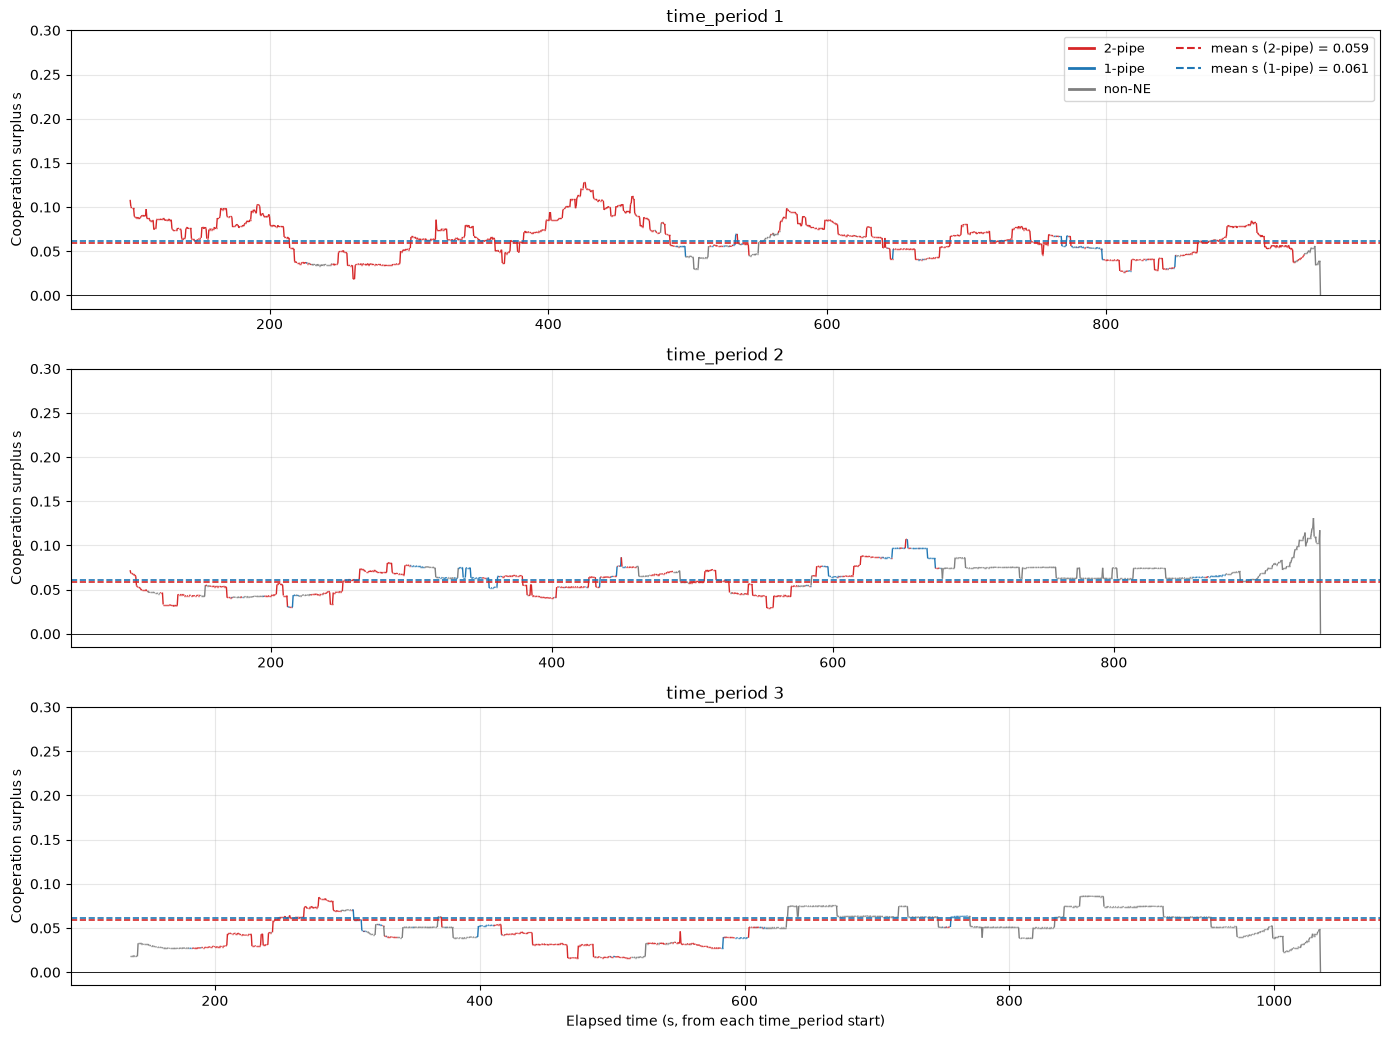

regime別の平均s: 2-pipe=0.059, 1-pipe=0.061  (論文: 2-pipe=0.15, 1-pipe=0.11)


In [21]:
plot_surplus_by_regime(df_regime,ylim=(-0.015, 0.30)) 

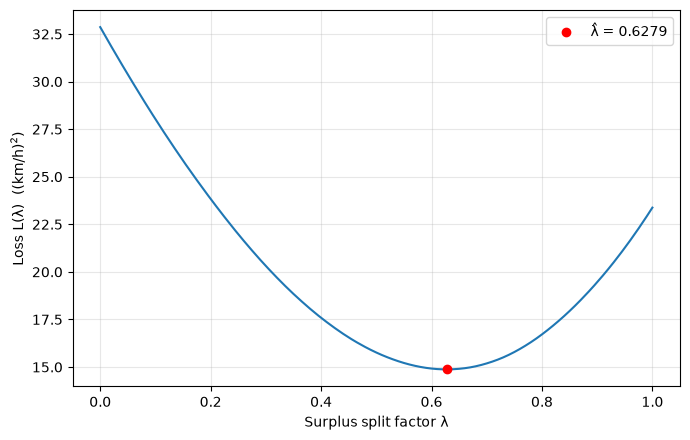

In [19]:

plot_surplus_split_loss(res['train'], results_cc_strong_constraint, results_tt_strong_constraint, res['lambda_hat'])